In [14]:
from dotenv import load_dotenv
load_dotenv()

True

In [15]:
from pydantic import BaseModel
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from typing import Annotated

In [16]:
class ChatState(BaseModel):
    messages:Annotated[list,add_messages]

In [17]:
llm = ChatGroq(model = "openai/gpt-oss-20b")

In [18]:
def ChatBotNode(state:ChatState) -> ChatState:
    res = llm.invoke(state.messages)
    state.messages = [res]
    return state

In [19]:
memory = InMemorySaver()

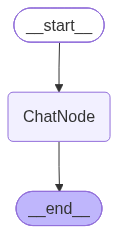

In [20]:
graph = StateGraph(ChatState)
graph.add_node("ChatNode",ChatBotNode)

graph.add_edge(START,"ChatNode")
graph.add_edge("ChatNode",END)

graph.compile(checkpointer=memory)

In [28]:
config = {"configurable":{"thread_id":1}}
res = graph.compile(checkpointer=memory).invoke(
	{"messages": [{"role": "user", "content": "Hello What is my name"}]},
	config,
)

In [29]:
print(res["messages"][-1].content)

You mentioned earlier that your name is **Aryan Dogra**. Let me know if there’s anything else you’d like to discuss!
